[Saved] E:\CAZ-Again\Figure1\Figs\AllRegions_DroughtDemand_60m_occupancy_overlay.png
[Saved] E:\CAZ-Again\Figure1\Figs\AllRegions_WetRelief_60m_occupancy_overlay.png
[Saved data] E:\CAZ-Again\Figure1\Figs\AllRegions_DroughtDemand_60m_occupancy_overlay.csv
[Saved data] E:\CAZ-Again\Figure1\Figs\AllRegions_WetRelief_60m_occupancy_overlay.csv


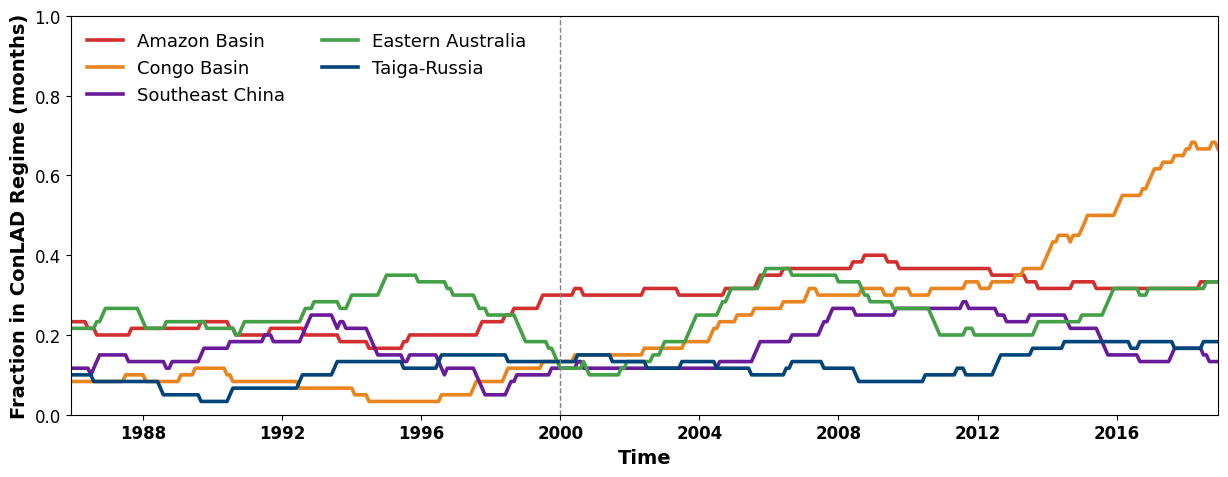

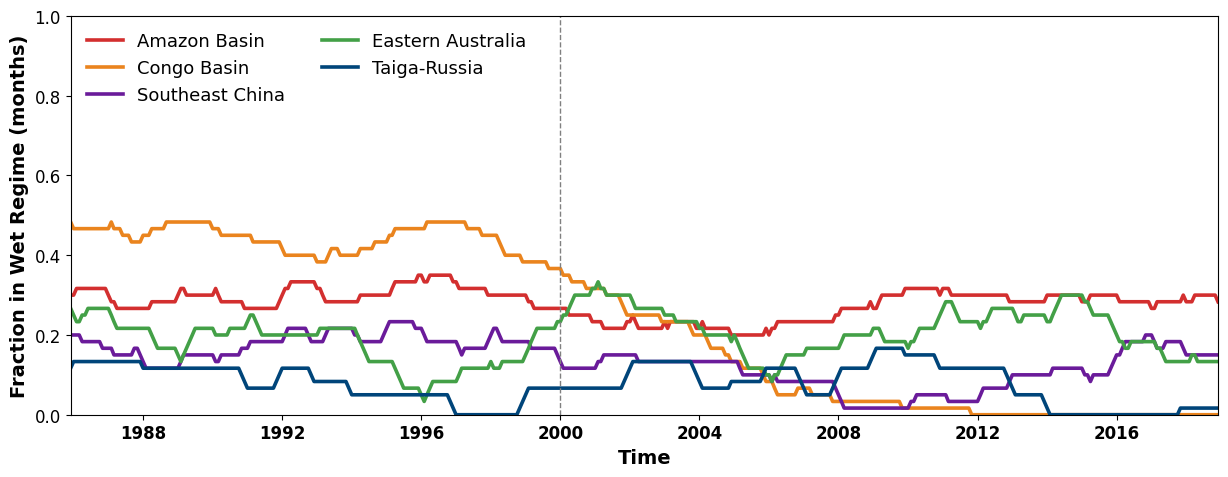

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import scipy.io as sio

# ---- Global Font Configuration (Scaled Up Natively) ----
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,            # Increased base font size
    "axes.labelsize": 14,       # Increased axis label base size
    "legend.fontsize": 13,      # Increased legend font size
    "xtick.labelsize": 12,      # Increased x-tick numbers size
    "ytick.labelsize": 12       # Increased y-tick numbers size
})

# ---------------- Config ----------------
BASE = Path("E:/CAZ-Again/Figure1")

# UPDATED: new 1981-2018 SM/VPD file
mat_path = BASE / "Fareeha_data_SM_VPD_1981_2018.mat"

REGIONS = ["Amazon","Congo","China","QL","Taiga"]

PRETTY = {
    "Amazon":"Amazon Basin",
    "Congo":"Congo Basin",
    "China":"Southeast China",
    "QL":"Eastern Australia",
    "Taiga":"Taiga-Russia"
}

# ---- Color palette ----
PALETTE = {
    "Amazon Basin":      "#D32F2F",  # red
    "Congo Basin":       "#EA841E",  # orange
    "Southeast China":   "#6A1B9A",  # purple
    "Eastern Australia": "#43A047",  # green
    "Taiga-Russia":      "#00457A"   # blue
}

LINE_WIDTH = 2.6
ROLL       = 60

SPLIT_DATE = pd.Timestamp("2000-01-01")

FIG_DIR = BASE / "Figs"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE_DPI = 400

# Toggle whether to show the plots after saving
SHOW_AFTER_SAVE = True


# =============================================================================
# LOAD DRIVERS (SM, VPD)
# =============================================================================

mat = sio.loadmat(
    str(mat_path),
    squeeze_me=True
)


def get_series(prefix, region_key):

    keys = {
        k.lower(): k
        for k in mat.keys()
    }

    want = f"{prefix}_{region_key}".lower()

    if want in keys:

        arr = np.ravel(
            np.array(
                mat[keys[want]],
                dtype=float
            )
        )

        # UPDATED:
        # monthly record now begins January 1981
        idx = pd.period_range(
            "1981-01",
            "2018-12",
            freq="M"
        ).to_timestamp()

        n = min(
            len(arr),
            len(idx)
        )

        return pd.Series(
            arr[:n],
            index=idx[:n],
            name=prefix
        )

    return None


drivers = {}

for r in REGIONS:

    sm = get_series(
        "SM",
        r
    )

    vpd = get_series(
        "VPD",
        r
    )

    if sm is not None and vpd is not None:

        drivers[r] = {
            "SM": sm.astype(float),
            "VPD": vpd.astype(float)
        }


# =============================================================================
# REGIME LABELS — REGION-SPECIFIC TERCILES
#
# Drought–Demand:
#     SM <= 33.33rd percentile
#     VPD >= 66.67th percentile
#
# Wet–Relief:
#     SM >= 66.67th percentile
#     VPD <= 33.33rd percentile
#
# Mixed-Low:
#     SM <= 33.33rd percentile
#     VPD <= 33.33rd percentile
#
# Mixed-High:
#     SM >= 66.67th percentile
#     VPD >= 66.67th percentile
#
# Everything else:
#     Other
# =============================================================================

def regimes(sm, vpd):

    df = pd.concat(
        [
            sm.rename("SM"),
            vpd.rename("VPD")
        ],
        axis=1
    ).dropna()

    # Tercile thresholds
    qsm1, qsm2 = df.SM.quantile(
        [1/3, 2/3]
    )

    qv1, qv2 = df.VPD.quantile(
        [1/3, 2/3]
    )

    lab = pd.Series(
        "Other",
        index=df.index,
        dtype=object
    )

    # Low SM + High VPD
    lab[
        (df.SM <= qsm1) &
        (df.VPD >= qv2)
    ] = "Drought–Demand" # ConLAD

    # High SM + Low VPD
    lab[
        (df.SM >= qsm2) &
        (df.VPD <= qv1)
    ] = "Wet–Relief"

    # Low SM + Low VPD
    lab[
        (df.SM <= qsm1) &
        (df.VPD <= qv1)
    ] = "Mixed-Low"

    # High SM + High VPD
    lab[
        (df.SM >= qsm2) &
        (df.VPD >= qv2)
    ] = "Mixed-High"

    return (
        lab
        .reindex(sm.index)
        .fillna("Other")
    )


regime_ts = {
    r: regimes(
        drivers[r]["SM"],
        drivers[r]["VPD"]
    )
    for r in drivers
}


# =============================================================================
# ROLLING OCCUPANCY
#
# UPDATED:
# Every occupancy value must contain a COMPLETE 60-month window.
#
# Therefore:
# Jan 1981 - Dec 1985 -> first valid value at Dec 1985
#
# Occupancy =
# number of months in target regime / 60
# =============================================================================

def rolling_occ(
    series,
    label,
    window=60
):

    s = (
        series == label
    ).astype(float)

    return s.rolling(
        window=window,
        min_periods=window
    ).mean()


# =============================================================================
# COLLECT OCCUPANCY DATA
# =============================================================================

idx_ref = next(
    iter(
        regime_ts.values()
    )
).index


occ_drought = pd.DataFrame(
    index=idx_ref
)

occ_wet = pd.DataFrame(
    index=idx_ref
)


for r in REGIONS:

    if r in regime_ts:

        occ_drought[
            PRETTY[r]
        ] = rolling_occ(
            regime_ts[r],
            "Drought–Demand",   #ConLAD
            ROLL
        )

        occ_wet[
            PRETTY[r]
        ] = rolling_occ(
            regime_ts[r],
            "Wet–Relief",    #wet_Regime
            ROLL
        )


# =============================================================================
# HELPER TO FIND VALID X-SPAN
# Removes blank area created by the first 59 NaN months
# =============================================================================

def valid_xlim(
    df: pd.DataFrame
):

    any_valid = (
        df
        .notna()
        .any(axis=1)
        .values
    )

    if not any_valid.any():

        return (
            df.index[0],
            df.index[-1]
        )

    # First valid rolling value
    i0 = np.argmax(
        any_valid
    )

    # Last valid rolling value
    i1 = (
        len(any_valid)
        - 1
        - np.argmax(
            any_valid[::-1]
        )
    )

    return (
        df.index[i0],
        df.index[i1]
    )


# =============================================================================
# HELPER: PLOT OVERLAY
# Legend INSIDE, 2 columns
#
# Plot customization retained unchanged.
# =============================================================================

def plot_overlay(
    df,
    ylab,
    png_name,
    deltaP_texts=None,
    colorbar=None,
    cbar_label=None
):

    fig, ax = plt.subplots(
        figsize=(12.5, 5.0)
    )

    for label in df.columns:

        ax.plot(
            df.index,
            df[label].values,
            linewidth=LINE_WIDTH,
            label=label,
            color=PALETTE.get(
                label,
                None
            )
        )

    # Split line (grey)
    ax.axvline(
        SPLIT_DATE,
        linestyle="--",
        linewidth=1,
        color="0.5"
    )

    ax.set_ylim(
        0,
        1
    )

    # Labels with prominent font sizes
    ax.set_ylabel(
        ylab,
        fontweight="bold",
        fontsize=14
    )

    ax.set_xlabel(
        "Time",
        fontweight="bold",
        fontsize=14
    )

    # Tick label sizes & weights
    ax.tick_params(
        axis="x",
        labelsize=12
    )

    ax.tick_params(
        axis="y",
        labelsize=12
    )

    for t in ax.get_xticklabels():

        t.set_fontweight(
            "bold"
        )

    for t in ax.get_yticklabels():

        t.set_fontweight(
            "normal"
        )

    # Trim x-limits to actual valid 60-month data span
    x0, x1 = valid_xlim(
        df
    )

    ax.set_xlim(
        x0,
        x1
    )

    ax.margins(
        x=0,
        y=0.02
    )

    # Legend INSIDE the plotting area, 2 columns, no frame
    ax.legend(
        ncol=2,
        loc="upper left",
        frameon=False,
        prop={
            "weight": "normal",
            "size": 13
        }
    )

    # Colorbar dynamic adjustments if one exists
    if colorbar is not None:

        if cbar_label is not None:

            colorbar.set_label(
                cbar_label,
                fontsize=12
            )

        colorbar.ax.tick_params(
            labelsize=12
        )

    # ΔP annotations above each region line
    if (
        isinstance(
            deltaP_texts,
            dict
        )
        and len(deltaP_texts) > 0
    ):

        for col in df.columns:

            if col in deltaP_texts:

                ser = (
                    df[col]
                    .dropna()
                )

                if not ser.empty:

                    x_last = (
                        ser.index[-1]
                    )

                    y_last = (
                        ser.iloc[-1]
                    )

                    ax.annotate(
                        deltaP_texts[col],
                        xy=(
                            x_last,
                            min(
                                0.98,
                                max(
                                    0.02,
                                    y_last + 0.04
                                )
                            )
                        ),
                        xytext=(5, 0),
                        textcoords="offset points",
                        ha="left",
                        va="center",
                        fontsize=11,
                        fontweight="bold"
                    )

    fig.tight_layout()

    out_png = (
        FIG_DIR /
        png_name
    )

    fig.savefig(
        out_png,
        dpi=SAVE_DPI,
        bbox_inches="tight"
    )

    return (
        fig,
        out_png
    )


# =============================================================================
# FIGURE 1a — DROUGHT–DEMAND OCCUPANCY
# =============================================================================

fig1, png1 = plot_overlay(
    occ_drought,
    "Fraction in ConLAD Regime (months)",
    "AllRegions_DroughtDemand_60m_occupancy_overlay.png"
)


occ_drought.to_csv(
    FIG_DIR /
    "AllRegions_DroughtDemand_60m_occupancy_overlay.csv",
    index=True
)


# =============================================================================
# FIGURE 1b — WET–RELIEF OCCUPANCY
# =============================================================================

fig2, png2 = plot_overlay(
    occ_wet,
    "Fraction in Wet Regime (months)",
    "AllRegions_WetRelief_60m_occupancy_overlay.png"
)


occ_wet.to_csv(
    FIG_DIR /
    "AllRegions_WetRelief_60m_occupancy_overlay.csv",
    index=True
)


# =============================================================================
# SAVED FILE INFORMATION
# =============================================================================

print(
    f"[Saved] {png1}"
)

print(
    f"[Saved] {png2}"
)

print(
    f"[Saved data] "
    f"{FIG_DIR / 'AllRegions_DroughtDemand_60m_occupancy_overlay.csv'}"
)

print(
    f"[Saved data] "
    f"{FIG_DIR / 'AllRegions_WetRelief_60m_occupancy_overlay.csv'}"
)


# =============================================================================
# DISPLAY AFTER SAVING
# =============================================================================

if SHOW_AFTER_SAVE:

    plt.show()

    plt.close(
        fig1
    )

    plt.close(
        fig2
    )

else:

    plt.close(
        fig1
    )

    plt.close(
        fig2
    )